# 01 - Market Data & Solar Capture Analysis

# Objective

Build a clean hourly dataset combining German day-ahead electricity prices and solar generation to analyse:

- Day-ahead electricity prices
- Solar generation profiles
- Negative-price periods
- Solar capture price
- Capture rate
- Price-volume correlation


## Key Findings

- The annual solar capture rate declined from **77.9% in 2021 to 51.6% in 2025**, while the capture discount increased from **€21.40/MWh to €43.25/MWh**.
- Capture risk is strongly seasonal. In 2025, monthly capture rates fell to approximately **31–40% between April and June**, compared with around 100% during winter months.
- Negative\-price exposure increased sharply: negative\-price hours rose from **139 to 573**, while the share of solar generation produced during those hours increased from **4.2% to 24.1%**.
- The annual price\-solar correlation deteriorated from **\-0.19 to \-0.56**. In spring and summer 2025, monthly correlations reached approximately **\-0.64 to \-0.75**.
- **2022 was an exceptional high\-price regime**, with a 94.4% capture rate despite the underlying solar generation profile.

Overall, the analysis shows that annual baseload prices do not adequately represent the market value of solar generation. A pay\-as\-produced solar PPA must incorporate hourly production shape, seasonal capture effects, negative\-price exposure and price\-volume correlation.



In [191]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready")

Environment ready


## Data

This analysis uses publicly available German electricity-market data from SMARD, the market-data platform of the German Federal Network Agency (Bundesnetzagentur).

The initial dataset combines:

- DE-LU hourly day-ahead electricity prices
- German hourly photovoltaic generation

The historical analysis covers 2021-2025. Data are used under the SMARD CC BY 4.0 licence.


### A. Raw Data Inspection

Before combining the historical datasets, we inspect the raw SMARD exports to validate their structure, units and timestamp format.

In [192]:
from pathlib import Path

DATA_DIR = Path("../data/raw")

price_files = sorted((DATA_DIR / "prices").glob("*.csv"))
solar_files = sorted((DATA_DIR / "solar").glob("*.csv"))

print("Price files:", len(price_files))
print("Solar files:", len(solar_files))

print("\nPrice files:")
for file in price_files:
    print("-", file.name)

print("\nSolar files:")
for file in solar_files:
    print("-", file.name)

Price files: 3
Solar files: 3

Price files:
- Day-ahead_prices_202101010000_202301010000_Hour.csv
- Day-ahead_prices_202301010000_202501010000_Hour.csv
- Day-ahead_prices_202501010000_202601010000_Hour.csv

Solar files:
- Actual_generation_202101010000_202301010000_Hour.csv
- Actual_generation_202301010000_202501010000_Hour.csv
- Actual_generation_202501010000_202601010000_Hour.csv


In [193]:
price_sample = pd.read_csv(price_files[0], sep=";")
solar_sample = pd.read_csv(solar_files[0], sep=";")

print("PRICE DATA")
print("Shape:", price_sample.shape)
print("Columns:", price_sample.columns.tolist())
display(price_sample.head())

print("\nSOLAR DATA")
print("Shape:", solar_sample.shape)
print("Columns:", solar_sample.columns.tolist())
display(solar_sample.head())


print("PRICE DTYPES")
print(price_sample.dtypes)

print("\nSOLAR DTYPES")
print(solar_sample.dtypes)

PRICE DATA
Shape: (17520, 19)
Columns: ['Start date', 'End date', 'Germany/Luxembourg [€/MWh] Calculated resolutions', '∅ DE/LU neighbours [€/MWh] Calculated resolutions', 'Belgium [€/MWh] Calculated resolutions', 'Denmark 1 [€/MWh] Calculated resolutions', 'Denmark 2 [€/MWh] Calculated resolutions', 'France [€/MWh] Calculated resolutions', 'Netherlands [€/MWh] Calculated resolutions', 'Norway 2 [€/MWh] Calculated resolutions', 'Austria [€/MWh] Calculated resolutions', 'Poland [€/MWh] Calculated resolutions', 'Sweden 4 [€/MWh] Calculated resolutions', 'Switzerland [€/MWh] Calculated resolutions', 'Czech Republic [€/MWh] Calculated resolutions', 'DE/AT/LU [€/MWh] Calculated resolutions', 'Northern Italy [€/MWh] Calculated resolutions', 'Slovenia [€/MWh] Calculated resolutions', 'Hungary [€/MWh] Calculated resolutions']


,Start date,End date,Germany/Luxembourg [€/MWh] Calculated resolutions,∅ DE/LU neighbours [€/MWh] Calculated resolutions,Belgium [€/MWh] Calculated resolutions,Denmark 1 [€/MWh] Calculated resolutions,Denmark 2 [€/MWh] Calculated resolutions,France [€/MWh] Calculated resolutions,Netherlands [€/MWh] Calculated resolutions,Norway 2 [€/MWh] Calculated resolutions,Austria [€/MWh] Calculated resolutions,Poland [€/MWh] Calculated resolutions,Sweden 4 [€/MWh] Calculated resolutions,Switzerland [€/MWh] Calculated resolutions,Czech Republic [€/MWh] Calculated resolutions,DE/AT/LU [€/MWh] Calculated resolutions,Northern Italy [€/MWh] Calculated resolutions,Slovenia [€/MWh] Calculated resolutions,Hungary [€/MWh] Calculated resolutions
0,"Jan 1, 2021 12:00 AM","Jan 1, 2021 1:00 AM",50.87,44.17,50.87,50.87,50.87,50.87,50.87,24.95,50.87,34.18,24.95,50.98,45.54,-,50.87,50.87,45.54
1,"Jan 1, 2021 1:00 AM","Jan 1, 2021 2:00 AM",48.19,41.63,48.19,48.19,48.19,48.19,48.19,24.35,48.19,32.61,24.35,45.94,41.59,-,48.19,48.19,41.59
2,"Jan 1, 2021 2:00 AM","Jan 1, 2021 3:00 AM",44.68,39.38,44.68,44.68,44.68,44.68,44.68,23.98,44.68,32.58,23.98,44.53,40.05,-,44.68,44.68,40.05
3,"Jan 1, 2021 3:00 AM","Jan 1, 2021 4:00 AM",42.92,37.73,42.92,42.92,42.92,42.92,42.92,23.72,42.92,32.20,23.72,41.01,36.90,-,42.92,42.92,36.90
4,"Jan 1, 2021 4:00 AM","Jan 1, 2021 5:00 AM",40.39,35.70,40.39,40.39,40.39,40.39,40.39,23.73,40.39,29.16,23.73,39.23,34.47,-,40.39,40.39,34.47



SOLAR DATA
Shape: (17520, 14)
Columns: ['Start date', 'End date', 'Biomass [MWh] Calculated resolutions', 'Hydropower [MWh] Calculated resolutions', 'Wind offshore [MWh] Calculated resolutions', 'Wind onshore [MWh] Calculated resolutions', 'Photovoltaics [MWh] Calculated resolutions', 'Other renewable [MWh] Calculated resolutions', 'Nuclear [MWh] Calculated resolutions', 'Lignite [MWh] Calculated resolutions', 'Hard coal [MWh] Calculated resolutions', 'Fossil gas [MWh] Calculated resolutions', 'Hydro pumped storage [MWh] Calculated resolutions', 'Other conventional [MWh] Calculated resolutions']


,Start date,End date,Biomass [MWh] Calculated resolutions,Hydropower [MWh] Calculated resolutions,Wind offshore [MWh] Calculated resolutions,Wind onshore [MWh] Calculated resolutions,Photovoltaics [MWh] Calculated resolutions,Other renewable [MWh] Calculated resolutions,Nuclear [MWh] Calculated resolutions,Lignite [MWh] Calculated resolutions,Hard coal [MWh] Calculated resolutions,Fossil gas [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Other conventional [MWh] Calculated resolutions
0,"Jan 1, 2021 12:00 AM","Jan 1, 2021 1:00 AM","4,481.00","1,203.00",383.00,"3,928.25",1.00,213.00,"8,144.75","11,608.50","3,443.75","6,923.00",347.25,"1,637.50"
1,"Jan 1, 2021 1:00 AM","Jan 1, 2021 2:00 AM","4,453.00","1,192.75",394.50,"3,528.25",1.00,213.25,"8,150.25","11,602.75","3,044.75","6,688.00",518.50,"1,636.00"
2,"Jan 1, 2021 2:00 AM","Jan 1, 2021 3:00 AM","4,440.50","1,161.00",305.25,"3,198.00",1.00,216.50,"8,156.50","11,758.50","3,067.25","6,586.00",170.00,"1,630.00"
3,"Jan 1, 2021 3:00 AM","Jan 1, 2021 4:00 AM","4,424.75","1,177.75",319.25,"2,768.75",1.00,218.00,"8,153.75","12,337.50","2,852.50","6,396.50",2.00,"1,621.50"
4,"Jan 1, 2021 4:00 AM","Jan 1, 2021 5:00 AM","4,430.75","1,153.25",296.25,"2,462.25",1.00,221.50,"8,150.50","12,395.00","2,713.25","6,333.00",6.00,"1,621.50"


PRICE DTYPES
Start date                                               str
End date                                                 str
Germany/Luxembourg [€/MWh] Calculated resolutions    float64
∅ DE/LU neighbours [€/MWh] Calculated resolutions    float64
Belgium [€/MWh] Calculated resolutions               float64
Denmark 1 [€/MWh] Calculated resolutions             float64
Denmark 2 [€/MWh] Calculated resolutions             float64
France [€/MWh] Calculated resolutions                    str
Netherlands [€/MWh] Calculated resolutions           float64
Norway 2 [€/MWh] Calculated resolutions              float64
Austria [€/MWh] Calculated resolutions               float64
Poland [€/MWh] Calculated resolutions                float64
Sweden 4 [€/MWh] Calculated resolutions              float64
Switzerland [€/MWh] Calculated resolutions           float64
Czech Republic [€/MWh] Calculated resolutions        float64
DE/AT/LU [€/MWh] Calculated resolutions                  str
Northern It

Relevant Columns and Data Types

For the historical capture analysis, only two market variables are required:

- **DE-LU day-ahead electricity price** in EUR/MWh
- **German photovoltaic generation** in MWh

Before cleaning and merging the full 2021-2025 dataset, we verify how these columns were interpreted by pandas and inspect a sample of their raw values.

This step ensures that prices and generation are stored as numerical variables rather than text before any calculations are performed.

In [194]:
PRICE_COL = "Germany/Luxembourg [€/MWh] Calculated resolutions"
SOLAR_COL = "Photovoltaics [MWh] Calculated resolutions"

print("Price column type:", price_sample[PRICE_COL].dtype)
print("Solar column type:", solar_sample[SOLAR_COL].dtype)

print("\nSample price values:")
print(price_sample[PRICE_COL].head())

print("\nSample solar values:")
print(solar_sample[SOLAR_COL].head())

Price column type: float64
Solar column type: str

Sample price values:
0    50.87
1    48.19
2    44.68
3    42.92
4    40.39
Name: Germany/Luxembourg [€/MWh] Calculated resolutions, dtype: float64

Sample solar values:
0    1.00
1    1.00
2    1.00
3    1.00
4    1.00
Name: Photovoltaics [MWh] Calculated resolutions, dtype: str


### B. Numeric Data Cleaning

The DE-LU day-ahead price series is already stored as a numerical variable.

Photovoltaic generation is imported as text because SMARD uses commas as thousands separators (e.g. `4,481.00` MWh). The series must therefore be converted to a numerical format before calculating revenues, capture prices or correlations.

The raw files remain unchanged; all transformations are performed programmatically to ensure reproducibility.

In [195]:
solar_clean = (
    solar_sample[SOLAR_COL]
    .str.replace(",", "", regex=False)
    .replace("-", np.nan)
    .astype(float)
)

print("Original type:", solar_sample[SOLAR_COL].dtype)
print("Clean type:", solar_clean.dtype)

display(
    pd.DataFrame({
        "raw": solar_sample[SOLAR_COL].head(10),
        "clean": solar_clean.head(10)
    })
)

Original type: str
Clean type: float64


,raw,clean
0,1.00,1.00
1,1.00,1.00
2,1.00,1.00
3,1.00,1.00
4,1.00,1.00
5,1.00,1.00
6,1.00,1.00
7,1.25,1.25
8,191.75,191.75
9,"1,334.75",1334.75


(why it is not 0 during the night ? maybe it was left like that for capture price calculation)

## C. Historical Dataset Construction

The validated SMARD files are now combined into continuous 2021-2025 time series.

The process consists of three steps:

1. Clean each raw price and solar-generation file using a consistent methodology.
2. Concatenate the three historical periods into continuous price and solar datasets.
3. Merge both datasets on their hourly delivery intervals.

Before calculating capture prices, the merged dataset is checked for duplicates, missing observations and timestamp inconsistencies.

In [196]:
def load_price_file(file_path):
    df = pd.read_csv(file_path, sep=";")

    df = df[
        ["Start date", "End date", PRICE_COL]
    ].copy()

    df = df.rename(columns={
        "Start date": "start_date",
        "End date": "end_date",
        PRICE_COL: "price_eur_mwh"
    })

    return df


def load_solar_file(file_path):
    df = pd.read_csv(file_path, sep=";")

    df = df[
        ["Start date", "End date", SOLAR_COL]
    ].copy()

    df = df.rename(columns={
        "Start date": "start_date",
        "End date": "end_date",
        SOLAR_COL: "solar_generation_mwh"
    })

    df["solar_generation_mwh"] = (
        df["solar_generation_mwh"]
        .str.replace(",", "", regex=False)
        .replace("-", np.nan)
        .astype(float)
    )

    return df

In [197]:
prices = pd.concat(
    [load_price_file(file) for file in price_files],
    ignore_index=True
)

solar = pd.concat(
    [load_solar_file(file) for file in solar_files],
    ignore_index=True
)

print("Prices shape:", prices.shape)
print("Solar shape:", solar.shape)

display(prices.head())
display(solar.head())

Prices shape: (43824, 3)
Solar shape: (43824, 3)


,start_date,end_date,price_eur_mwh
0,"Jan 1, 2021 12:00 AM","Jan 1, 2021 1:00 AM",50.87
1,"Jan 1, 2021 1:00 AM","Jan 1, 2021 2:00 AM",48.19
2,"Jan 1, 2021 2:00 AM","Jan 1, 2021 3:00 AM",44.68
3,"Jan 1, 2021 3:00 AM","Jan 1, 2021 4:00 AM",42.92
4,"Jan 1, 2021 4:00 AM","Jan 1, 2021 5:00 AM",40.39


,start_date,end_date,solar_generation_mwh
0,"Jan 1, 2021 12:00 AM","Jan 1, 2021 1:00 AM",1.0
1,"Jan 1, 2021 1:00 AM","Jan 1, 2021 2:00 AM",1.0
2,"Jan 1, 2021 2:00 AM","Jan 1, 2021 3:00 AM",1.0
3,"Jan 1, 2021 3:00 AM","Jan 1, 2021 4:00 AM",1.0
4,"Jan 1, 2021 4:00 AM","Jan 1, 2021 5:00 AM",1.0


## D. Timestamp Validation

The concatenated price and solar datasets each contain 43,824 hourly observations covering 2021-2025.

Before merging both datasets, delivery-period timestamps are converted from text to datetime objects and checked for:

- Missing timestamps
- Duplicate delivery intervals
- Consistency between price and solar datasets
- Potential daylight-saving-time effects

This validation ensures that each electricity price observation is matched with the correct solar-generation interval.

In [198]:
DATE_FORMAT = "%b %d, %Y %I:%M %p"

for df in [prices, solar]:
    df["start_date"] = pd.to_datetime(
        df["start_date"],
        format=DATE_FORMAT
    )
    df["end_date"] = pd.to_datetime(
        df["end_date"],
        format=DATE_FORMAT
    )



display(prices.head())
display(solar.head())

,start_date,end_date,price_eur_mwh
0,2021-01-01 00:00:00,2021-01-01 01:00:00,50.87
1,2021-01-01 01:00:00,2021-01-01 02:00:00,48.19
2,2021-01-01 02:00:00,2021-01-01 03:00:00,44.68
3,2021-01-01 03:00:00,2021-01-01 04:00:00,42.92
4,2021-01-01 04:00:00,2021-01-01 05:00:00,40.39


,start_date,end_date,solar_generation_mwh
0,2021-01-01 00:00:00,2021-01-01 01:00:00,1.0
1,2021-01-01 01:00:00,2021-01-01 02:00:00,1.0
2,2021-01-01 02:00:00,2021-01-01 03:00:00,1.0
3,2021-01-01 03:00:00,2021-01-01 04:00:00,1.0
4,2021-01-01 04:00:00,2021-01-01 05:00:00,1.0


### E. Timestamp Integrity Checks

Before merging electricity prices and solar generation, the hourly delivery periods are validated for duplicate timestamps, missing values and consistency between both datasets.

This step prevents price observations from being matched with the wrong generation intervals.

In [199]:
print("Price duplicate start dates:", prices["start_date"].duplicated().sum())
print("Solar duplicate start dates:", solar["start_date"].duplicated().sum())

print("\nPrice missing values:")
print(prices.isna().sum())

print("\nSolar missing values:")
print(solar.isna().sum())

print(
    "\nMatching timestamps:",
    prices["start_date"].equals(solar["start_date"])
)

price_duplicates = prices[
    prices["start_date"].duplicated(keep=False)
]

display(price_duplicates)

Price duplicate start dates: 5
Solar duplicate start dates: 5

Price missing values:
start_date       0
end_date         0
price_eur_mwh    0
dtype: int64

Solar missing values:
start_date              0
end_date                0
solar_generation_mwh    0
dtype: int64

Matching timestamps: True


,start_date,end_date,price_eur_mwh
7273,2021-10-31 02:00:00,2021-10-31 03:00:00,69.03
7274,2021-10-31 02:00:00,2021-10-31 03:00:00,64.49
16009,2022-10-30 02:00:00,2022-10-30 03:00:00,100.20
16010,2022-10-30 02:00:00,2022-10-30 03:00:00,99.92
24745,2023-10-29 02:00:00,2023-10-29 03:00:00,0.01
24746,2023-10-29 02:00:00,2023-10-29 03:00:00,0.02
33481,2024-10-27 02:00:00,2024-10-27 03:00:00,82.23
33482,2024-10-27 02:00:00,2024-10-27 03:00:00,80.43
42217,2025-10-26 02:00:00,2025-10-26 03:00:00,3.19
42218,2025-10-26 02:00:00,2025-10-26 03:00:00,2.02


### F. Daylight-Saving-Time Handling

The duplicate timestamps correspond exclusively to the annual transition from summer time to winter time, when the 02:00–03:00 delivery interval occurs twice.

Both observations represent distinct physical delivery hours and must therefore be preserved.

To avoid a many-to-many merge, each repeated delivery interval is assigned an occurrence number. Price and solar-generation data can then be matched uniquely using the start time, end time and occurrence number.

In [200]:
prices["occurrence"] = (
    prices.groupby(["start_date", "end_date"]).cumcount()
)

solar["occurrence"] = (
    solar.groupby(["start_date", "end_date"]).cumcount()
)


display(
    prices[prices["start_date"].duplicated(keep=False)]   #to keep both duplicates, use keep=False
)


,start_date,end_date,price_eur_mwh,occurrence
7273,2021-10-31 02:00:00,2021-10-31 03:00:00,69.03,0
7274,2021-10-31 02:00:00,2021-10-31 03:00:00,64.49,1
16009,2022-10-30 02:00:00,2022-10-30 03:00:00,100.20,0
16010,2022-10-30 02:00:00,2022-10-30 03:00:00,99.92,1
24745,2023-10-29 02:00:00,2023-10-29 03:00:00,0.01,0
24746,2023-10-29 02:00:00,2023-10-29 03:00:00,0.02,1
33481,2024-10-27 02:00:00,2024-10-27 03:00:00,82.23,0
33482,2024-10-27 02:00:00,2024-10-27 03:00:00,80.43,1
42217,2025-10-26 02:00:00,2025-10-26 03:00:00,3.19,0
42218,2025-10-26 02:00:00,2025-10-26 03:00:00,2.02,1


In [201]:
market = prices.merge(
    solar,
    on=["start_date", "end_date", "occurrence"],
    how="inner",
    validate="one_to_one"
)

print("Merged shape:", market.shape)
display(market.head())

Merged shape: (43824, 5)


,start_date,end_date,price_eur_mwh,occurrence,solar_generation_mwh
0,2021-01-01 00:00:00,2021-01-01 01:00:00,50.87,0,1.0
1,2021-01-01 01:00:00,2021-01-01 02:00:00,48.19,0,1.0
2,2021-01-01 02:00:00,2021-01-01 03:00:00,44.68,0,1.0
3,2021-01-01 03:00:00,2021-01-01 04:00:00,42.92,0,1.0
4,2021-01-01 04:00:00,2021-01-01 05:00:00,40.39,0,1.0


### G. Final Dataset Validation

The price and solar-generation datasets were successfully merged into a single hourly market dataset containing 43,824 observations from 2021 to 2025.

Before performing the capture analysis, final checks are applied to validate:

- Historical coverage
- Hourly delivery intervals
- Missing values
- Duplicate merge keys
- Negative electricity prices
- Non-negative solar generation

These controls ensure that subsequent market and revenue metrics are calculated from a consistent historical dataset.

In [202]:
print("Period:")
print(market["start_date"].min(), "to", market["end_date"].max())

print("\nMissing values:")
print(market.isna().sum())

print("\nDuplicate merge keys:")
print(
    market.duplicated(
        subset=["start_date", "end_date", "occurrence"]
    ).sum()
)

print("\nDelivery interval distribution:")
print(
    (market["end_date"] - market["start_date"])
    .value_counts()
)

print("\nNegative price hours:")
print((market["price_eur_mwh"] < 0).sum())

print("\nNegative solar observations:")
print((market["solar_generation_mwh"] < 0).sum())

print("\nPrice range:")
print(
    market["price_eur_mwh"].min(),
    "to",
    market["price_eur_mwh"].max(),
    "EUR/MWh"
)

print("\nSolar generation range:")
print(
    market["solar_generation_mwh"].min(),
    "to",
    market["solar_generation_mwh"].max(),
    "MWh"
)

Period:
2021-01-01 00:00:00 to 2026-01-01 00:00:00

Missing values:
start_date              0
end_date                0
price_eur_mwh           0
occurrence              0
solar_generation_mwh    0
dtype: int64

Duplicate merge keys:
0

Delivery interval distribution:
0 days 01:00:00    43824
Name: count, dtype: int64

Negative price hours:
1539

Negative solar observations:
0

Price range:
-500.0 to 936.28 EUR/MWh

Solar generation range:
0.0 to 52132.25 MWh


# Historical Market Analysis

Before calculating solar capture metrics, we analyse the historical behaviour of German day-ahead electricity prices and photovoltaic generation.

The analysis focuses on:

- Annual electricity-price dynamics
- Negative-price frequency and severity
- Solar-generation seasonality
- Intraday solar production profiles
- Relationship between solar generation and electricity prices

These patterns provide the economic context required to interpret solar capture prices and capture rates.


,average_price_eur_mwh,min_price_eur_mwh,max_price_eur_mwh,negative_price_hours,solar_generation_twh
year,,,,,
2021,96.85,-69.00,620.00,139,46.23
2022,235.45,-19.04,871.00,69,55.73
2023,95.18,-500.00,524.27,301,55.54
2024,78.51,-135.45,936.28,457,63.15
2025,89.32,-250.32,583.40,573,73.78


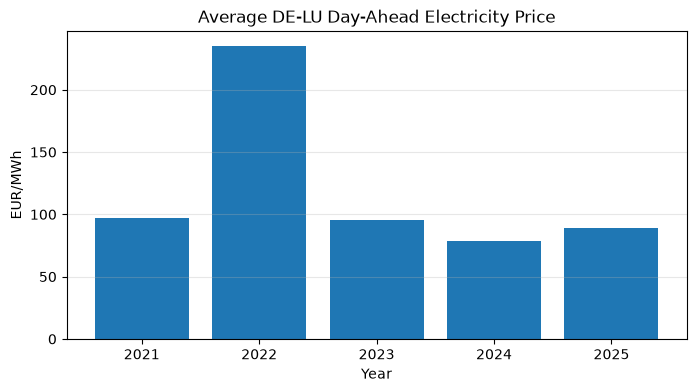

In [203]:
market["year"] = market["start_date"].dt.year

annual_summary = (
    market.groupby("year")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        min_price_eur_mwh=("price_eur_mwh", "min"),
        max_price_eur_mwh=("price_eur_mwh", "max"),
        negative_price_hours=("price_eur_mwh", lambda x: (x < 0).sum()),
        solar_generation_twh=("solar_generation_mwh", lambda x: x.sum() / 1e6),
    )
)

display(annual_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    annual_summary.index,
    annual_summary["average_price_eur_mwh"]
)

ax.set_title("Average DE-LU Day-Ahead Electricity Price")
ax.set_xlabel("Year")
ax.set_ylabel("EUR/MWh")
ax.grid(axis="y", alpha=0.3)

plt.show()

### 1. Negative-Price Frequency

Negative-price hours are particularly relevant for solar PPAs because photovoltaic generation is concentrated during daylight hours and can contribute to periods of oversupply.

An increasing frequency of negative prices can therefore reduce solar capture prices even when annual baseload prices remain relatively high.

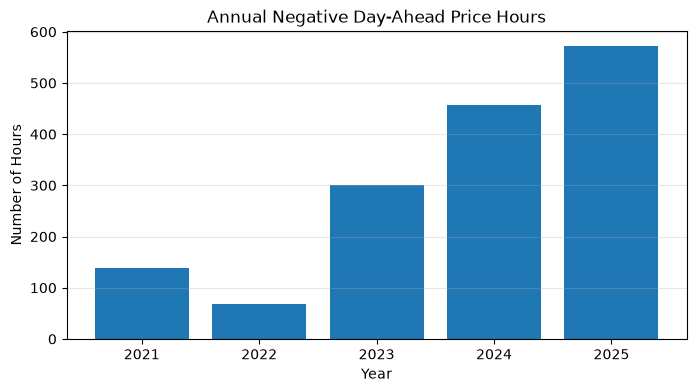

In [204]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    annual_summary.index,
    annual_summary["negative_price_hours"]
)

ax.set_title("Annual Negative Day-Ahead Price Hours")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Hours")
ax.grid(axis="y", alpha=0.3)

plt.show()


### 2.Intraday Solar Generation and Electricity Prices

To assess the relationship between solar production and electricity prices, hourly observations are grouped by hour of day.

Average photovoltaic generation and average DE-LU day-ahead prices are compared across the 24-hour daily cycle.

This provides a first indication of whether solar production is concentrated during hours associated with systematically lower electricity prices.

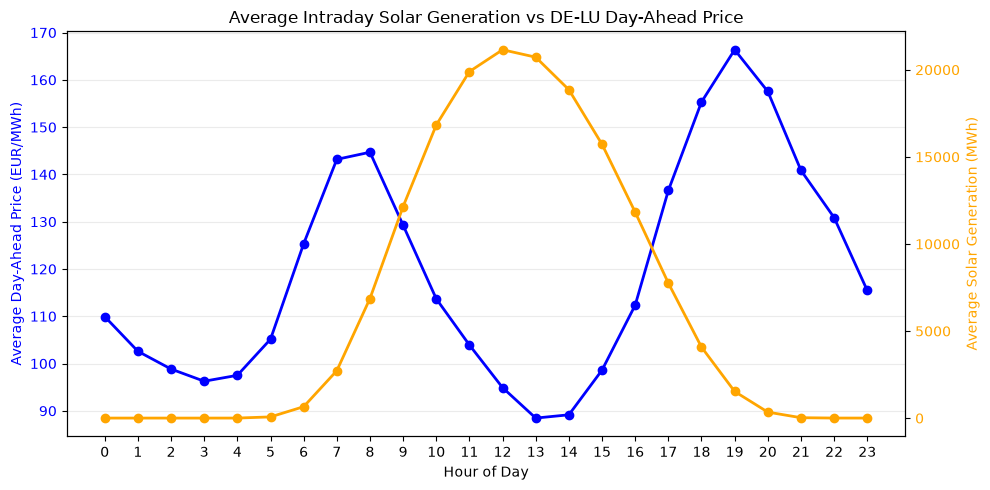

In [205]:
market["hour"] = market["start_date"].dt.hour

hourly_profile = (
    market.groupby("hour")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        average_solar_generation_mwh=("solar_generation_mwh", "mean")
    )
)

fig, ax_price = plt.subplots(figsize=(10, 5))

# Day-ahead price
ax_price.plot(
    hourly_profile.index,
    hourly_profile["average_price_eur_mwh"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Day-Ahead Price"
)

ax_price.set_xlabel("Hour of Day")
ax_price.set_ylabel("Average Day-Ahead Price (EUR/MWh)", color="blue")
ax_price.set_xticks(range(24))
ax_price.grid(axis="y", alpha=0.25)
ax_price.tick_params(axis="y", labelcolor="blue")

# Solar generation
ax_solar = ax_price.twinx()

ax_solar.plot(
    hourly_profile.index,
    hourly_profile["average_solar_generation_mwh"],
    color="orange",
    marker="o",
    linewidth=2,
    label="Solar Generation"
)

ax_solar.set_ylabel("Average Solar Generation (MWh)", color="orange")
ax_solar.tick_params(axis="y", labelcolor="orange")

plt.title("Average Intraday Solar Generation vs DE-LU Day-Ahead Price")

fig.tight_layout()
plt.show()


### 3.Daily Market and Solar Generation Dynamics

Hourly observations are aggregated to daily frequency to analyse how electricity prices and photovoltaic generation evolved over 2021-2025.

For each day:

- The DE-LU electricity price is calculated as the average hourly day-ahead price.
- Solar generation is calculated as total daily photovoltaic output.

This view highlights seasonal patterns, exceptional price regimes and the evolution of solar generation over time.

In [206]:
daily = (
    market.set_index("start_date")
    .resample("D")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        solar_generation_mwh=("solar_generation_mwh", "sum")
    )
)

daily["solar_generation_gwh"] = (
    daily["solar_generation_mwh"] / 1_000
)


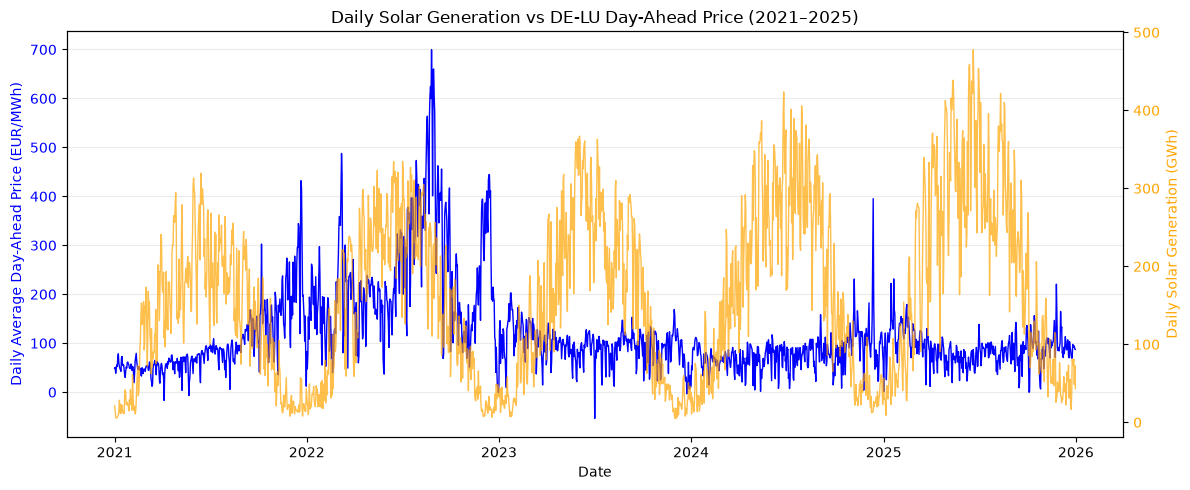

In [207]:
fig, ax_price = plt.subplots(figsize=(12, 5))

ax_price.plot(
    daily.index,
    daily["average_price_eur_mwh"],
    linewidth=1,
    color="blue"
)

ax_price.set_xlabel("Date")
ax_price.set_ylabel("Daily Average Day-Ahead Price (EUR/MWh)", color="blue")
ax_price.tick_params(axis="y", labelcolor="blue")
ax_price.grid(axis="y", alpha=0.25)

ax_solar = ax_price.twinx()

ax_solar.plot(
    daily.index,
    daily["solar_generation_gwh"],
    linewidth=1,
    color="orange",
    alpha=0.7
)

ax_solar.set_ylabel("Daily Solar Generation (GWh)", color="orange")
ax_solar.tick_params(axis="y", labelcolor="orange")

plt.title("Daily Solar Generation vs DE-LU Day-Ahead Price (2021–2025)")
fig.tight_layout()
plt.show()

### 4. Solar Capture Price & Capture Rate

The solar capture price measures the average electricity price received during hours of photovoltaic generation, weighted by the amount of solar electricity produced.

For each year:

**Solar Capture Price = Σ(Price × Solar Generation) / Σ(Solar Generation)**

The capture rate compares this production-weighted solar price with the average day-ahead market price:

**Capture Rate = Solar Capture Price / Average Day-Ahead Price**

A capture rate below 100% indicates that solar generation tends to occur during hours with below-average electricity prices.

In [208]:
market["solar_market_value_eur"] = (
    market["price_eur_mwh"]
    * market["solar_generation_mwh"]
)

In [209]:
capture_summary = (
    market.groupby("year")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        solar_generation_mwh=("solar_generation_mwh", "sum"),
        solar_market_value_eur=("solar_market_value_eur", "sum")
    )
)

capture_summary["capture_price_eur_mwh"] = (
    capture_summary["solar_market_value_eur"]
    / capture_summary["solar_generation_mwh"]
)

capture_summary["capture_rate_pct"] = (
    capture_summary["capture_price_eur_mwh"]
    / capture_summary["average_price_eur_mwh"]
    * 100
)

capture_summary["capture_discount_eur_mwh"] = (
    capture_summary["average_price_eur_mwh"]
    - capture_summary["capture_price_eur_mwh"]
)

display(
    capture_summary[
        [
            "average_price_eur_mwh",
            "capture_price_eur_mwh",
            "capture_rate_pct",
            "capture_discount_eur_mwh"
        ]
    ].round(2)
)

,average_price_eur_mwh,capture_price_eur_mwh,capture_rate_pct,capture_discount_eur_mwh
year,,,,
2021,96.85,75.45,77.90,21.40
2022,235.45,222.25,94.40,13.19
2023,95.18,72.17,75.83,23.00
2024,78.51,46.23,58.88,32.29
2025,89.32,46.07,51.58,43.25


### 5. Evolution of Solar Capture Value

The historical results show a growing divergence between average market prices and solar capture prices.

This divergence measures the economic impact of the solar generation profile: as photovoltaic output becomes increasingly concentrated during lower-price hours, the market value captured by solar generation can deteriorate relative to the baseload market price.

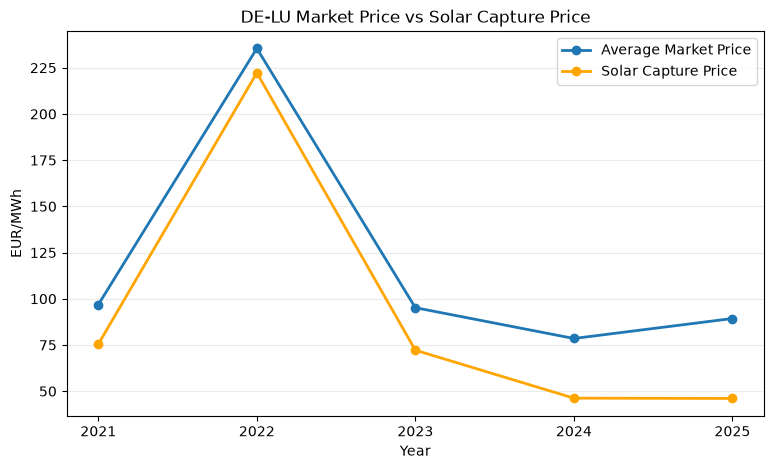

In [210]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    capture_summary.index,
    capture_summary["average_price_eur_mwh"],
    marker="o",
    linewidth=2,
    label="Average Market Price"
)

ax.plot(
    capture_summary.index,
    capture_summary["capture_price_eur_mwh"],
    marker="o",
    linewidth=2,
    color="orange",
    label="Solar Capture Price"
)

ax.set_title("DE-LU Market Price vs Solar Capture Price")
ax.set_xlabel("Year")
ax.set_ylabel("EUR/MWh")
ax.set_xticks(capture_summary.index)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.show()



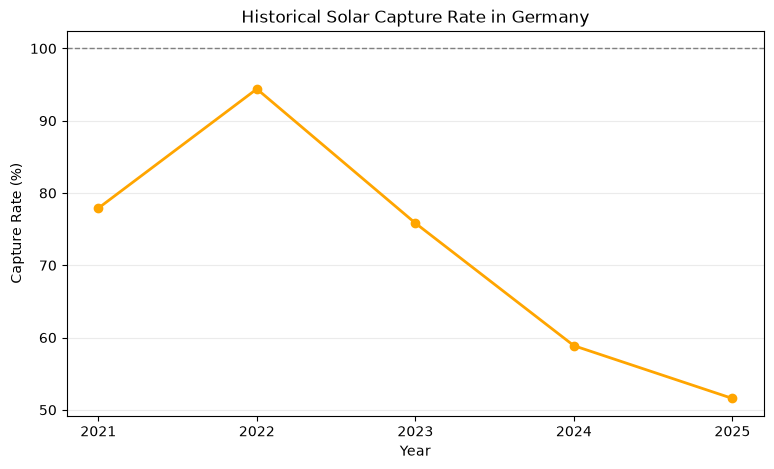

In [211]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    capture_summary.index,
    capture_summary["capture_rate_pct"],
    marker="o",
    linewidth=2,
    color="orange"
)

ax.axhline(
    100,
    color="grey",
    linestyle="--",
    linewidth=1
)

ax.set_title("Historical Solar Capture Rate in Germany")
ax.set_xlabel("Year")
ax.set_ylabel("Capture Rate (%)")
ax.set_xticks(capture_summary.index)
ax.grid(axis="y", alpha=0.25)

plt.show()

### 6. Interpreting the 2022 Capture Rate

2022 stands out as an exceptional market regime. The average DE-LU day-ahead price reached **€235.45/MWh**, while the solar capture price remained very high at **€222.25/MWh**, resulting in a **94.4% capture rate**.

This does not indicate an absence of solar capture risk. Rather, the unusually high overall level of electricity prices in 2022 meant that solar-producing hours also remained highly valuable in absolute terms. The capture discount was therefore limited to **€13.19/MWh**, despite the solar generation profile.

The following years show a very different pattern. As wholesale prices normalized, the solar capture price increasingly diverged from the average market price. By 2025, the average market price was **€89.32/MWh**, but solar captured only **€46.07/MWh**, reducing the capture rate to **51.6%** and increasing the capture discount to **€43.25/MWh**.

The comparison highlights an important distinction: **capture rate depends not only on the solar production profile, but also on the prevailing market regime and the hourly relationship between generation and prices.**

### 7. Monthly Solar Capture Rate

Annual capture rates can hide significant seasonal differences in the market value of solar generation.

Monthly capture rates are therefore calculated as:

**Monthly Capture Rate = Monthly Solar Capture Price / Monthly Average Day-Ahead Price**

where the solar capture price is the generation-weighted electricity price within each month.

A capture rate below 100% indicates that solar generation is concentrated in hours with below-average electricity prices. The monthly heatmap highlights when this capture discount is strongest throughout the year and how the pattern evolves over time.

In [212]:
market["month"] = market["start_date"].dt.to_period("M")

In [213]:
monthly_capture = (
    market.groupby("month")
    .agg(
        average_price_eur_mwh=(
            "price_eur_mwh",
            "mean"
        ),
        solar_generation_mwh=(
            "solar_generation_mwh",
            "sum"
        ),
        solar_market_value_eur=(
            "solar_market_value_eur",
            "sum"
        )
    )
)

In [214]:
monthly_capture["capture_price_eur_mwh"] = (
    monthly_capture["solar_market_value_eur"]
    / monthly_capture["solar_generation_mwh"]
)

monthly_capture["capture_rate_pct"] = (
    monthly_capture["capture_price_eur_mwh"]
    / monthly_capture["average_price_eur_mwh"]
    * 100
)

In [215]:
capture_rate_df = monthly_capture[
    ["capture_rate_pct"]
].copy()

capture_rate_df["year"] = (
    capture_rate_df.index.year
)

capture_rate_df["month_number"] = (
    capture_rate_df.index.month
)

capture_rate_matrix = capture_rate_df.pivot(
    index="year",
    columns="month_number",
    values="capture_rate_pct"
)

display(capture_rate_matrix.round(1))

month_number,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2021,105.0,92.1,87.0,84.8,78.5,92.6,91.0,92.9,91.2,91.8,103.8,122.7
2022,106.3,92.2,82.2,87.9,85.3,86.9,82.7,85.8,91.5,84.4,88.2,98.8
2023,104.4,96.1,86.7,79.7,66.1,75.3,67.6,80.2,74.1,77.5,93.5,96.0
2024,98.2,95.8,76.5,62.1,48.8,61.0,52.9,52.6,57.7,78.2,88.3,103.0
2025,101.2,86.3,53.6,40.2,32.2,31.4,68.1,50.8,53.0,85.0,90.3,101.1


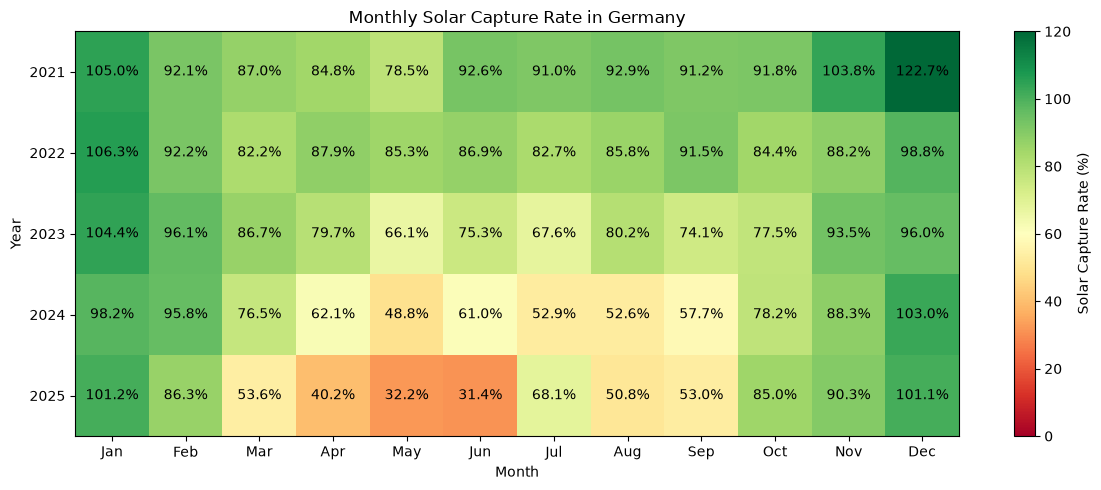

In [216]:
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(12, 5))

heatmap = ax.imshow(
    capture_rate_matrix.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=120,
    aspect="auto"
)

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(
    np.arange(len(capture_rate_matrix.index))
)
ax.set_yticklabels(
    capture_rate_matrix.index
)

ax.set_xlabel("Month")
ax.set_ylabel("Year")

ax.set_title(
    "Monthly Solar Capture Rate in Germany"
)

for i in range(capture_rate_matrix.shape[0]):
    for j in range(capture_rate_matrix.shape[1]):

        value = capture_rate_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center"
        )

fig.colorbar(
    heatmap,
    ax=ax,
    label="Solar Capture Rate (%)"
)

fig.tight_layout()
plt.show()

###8. Solar Exposure to Negative Prices

Negative electricity prices are particularly relevant for pay-as-produced solar PPAs because solar generation may remain exposed to the spot market during periods of oversupply.

Two complementary metrics are analysed for each year:

- **Negative-price hours:** number of hours when the DE-LU day-ahead price is below zero.
- **Solar generation exposed to negative prices:** share of annual photovoltaic generation produced during negative-price hours.

The second metric is particularly important because the economic impact of negative prices depends not only on their frequency, but also on whether solar assets are producing during those hours.


In [217]:
market["negative_price"] = market["price_eur_mwh"] < 0

In [218]:
negative_price_summary = (
    market.groupby("year")
    .agg(
        negative_price_hours=(
            "negative_price",
            "sum"
        ),
        total_solar_generation_mwh=(
            "solar_generation_mwh",
            "sum"
        ),
        solar_generation_negative_price_mwh=(
            "solar_generation_mwh",
            lambda x: x[market.loc[x.index, "negative_price"]].sum()
        )
    )
)

negative_price_summary["solar_negative_price_exposure_pct"] = (
    negative_price_summary["solar_generation_negative_price_mwh"]
    / negative_price_summary["total_solar_generation_mwh"]
    * 100
)

display(negative_price_summary.round(2))


,negative_price_hours,total_solar_generation_mwh,solar_generation_negative_price_mwh,solar_negative_price_exposure_pct
year,,,,
2021,139,46230946.00,1944117.75,4.21
2022,69,55727425.00,881802.00,1.58
2023,301,55544029.25,4622107.25,8.32
2024,457,63148433.00,11617454.75,18.40
2025,573,73783830.31,17807335.26,24.13


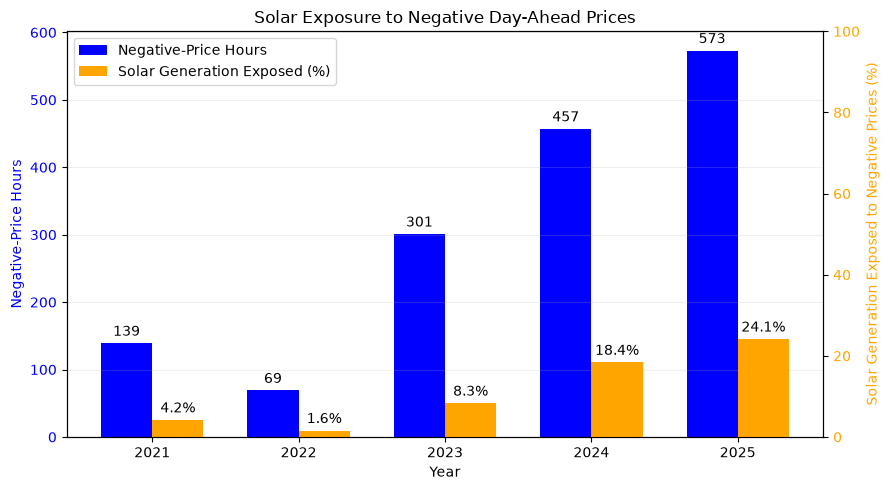

In [219]:
fig, ax_hours = plt.subplots(figsize=(9, 5))

# X-axis positions
x = np.arange(len(negative_price_summary.index))
width = 0.35

# Negative-price hours - left axis
bars_hours = ax_hours.bar(
    x - width / 2,
    negative_price_summary["negative_price_hours"],
    width,
    color="blue",
    label="Negative-Price Hours"
)

ax_hours.set_xlabel("Year")
ax_hours.set_ylabel("Negative-Price Hours", color="blue")
ax_hours.tick_params(axis="y", labelcolor="blue")

ax_hours.set_xticks(x)
ax_hours.set_xticklabels(negative_price_summary.index)

ax_hours.grid(
    axis="y",
    alpha=0.2
)

# Solar generation exposure - right axis
ax_solar = ax_hours.twinx()

bars_solar = ax_solar.bar(
    x + width / 2,
    negative_price_summary["solar_negative_price_exposure_pct"],
    width,
    color="orange",
    label="Solar Generation Exposed (%)"
)

ax_solar.set_ylabel(
    "Solar Generation Exposed to Negative Prices (%)",
    color="orange"
)

ax_solar.tick_params(
    axis="y",
    labelcolor="orange"
)

# Percentage axis from 0% to 100%
ax_solar.set_ylim(0, 100)

# Values above bars
ax_hours.bar_label(
    bars_hours,
    padding=3,
    fmt="%.0f"
)

ax_solar.bar_label(
    bars_solar,
    padding=3,
    fmt="%.1f%%"
)

# Title
ax_hours.set_title(
    "Solar Exposure to Negative Day-Ahead Prices"
)

# Combined legend
ax_hours.legend(
    [bars_hours, bars_solar],
    [
        "Negative-Price Hours",
        "Solar Generation Exposed (%)"
    ],
    loc="upper left"
)

fig.tight_layout()
plt.show()

### 9. Price-Volume Correlation

The relationship between photovoltaic generation and electricity prices is quantified using the annual correlation between hourly solar generation and DE-LU day-ahead prices.

A negative correlation indicates that higher solar generation tends to coincide with lower electricity prices, reinforcing the capture-price discount experienced by solar assets.

In [220]:
annual_correlation = (
    market.groupby("year")
    .apply(
        lambda x: x["price_eur_mwh"].corr(
            x["solar_generation_mwh"]
        ),
        include_groups=False
    )
    .rename("price_solar_correlation")
)

display(annual_correlation.round(3))

year
2021   -0.188
2022   -0.061
2023   -0.312
2024   -0.401
2025   -0.557
Name: price_solar_correlation, dtype: float64

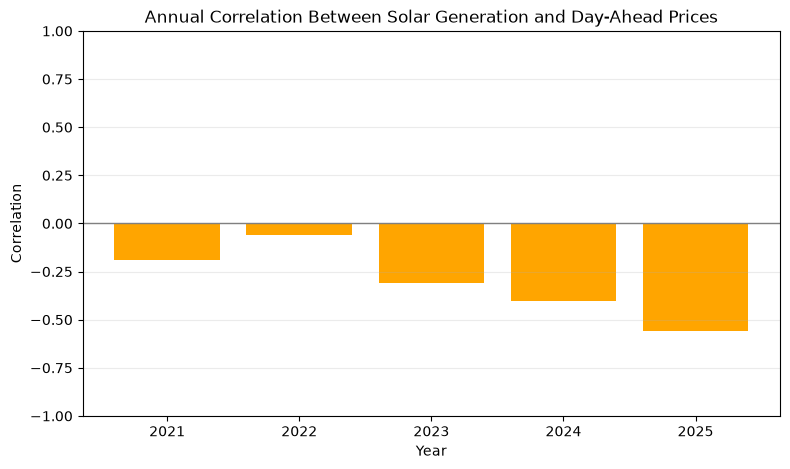

In [221]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    annual_correlation.index,
    annual_correlation.values,
    color="orange"
)

ax.axhline(
    0,
    color="grey",
    linewidth=1
)

ax.set_title("Annual Correlation Between Solar Generation and Day-Ahead Prices")
ax.set_xlabel("Year")
ax.set_ylabel("Correlation")
ax.set_xticks(annual_correlation.index)
ax.set_ylim(-1, 1)
ax.grid(axis="y", alpha=0.25)

plt.show()

In [222]:
market["month"] = market["start_date"].dt.to_period("M")

monthly_correlation = (
    market.groupby("month")
    .apply(
        lambda x: x["price_eur_mwh"].corr(
            x["solar_generation_mwh"]
        ),
        include_groups=False
    )
    .rename("price_solar_correlation")
)

monthly_correlation.index = monthly_correlation.index.to_timestamp()

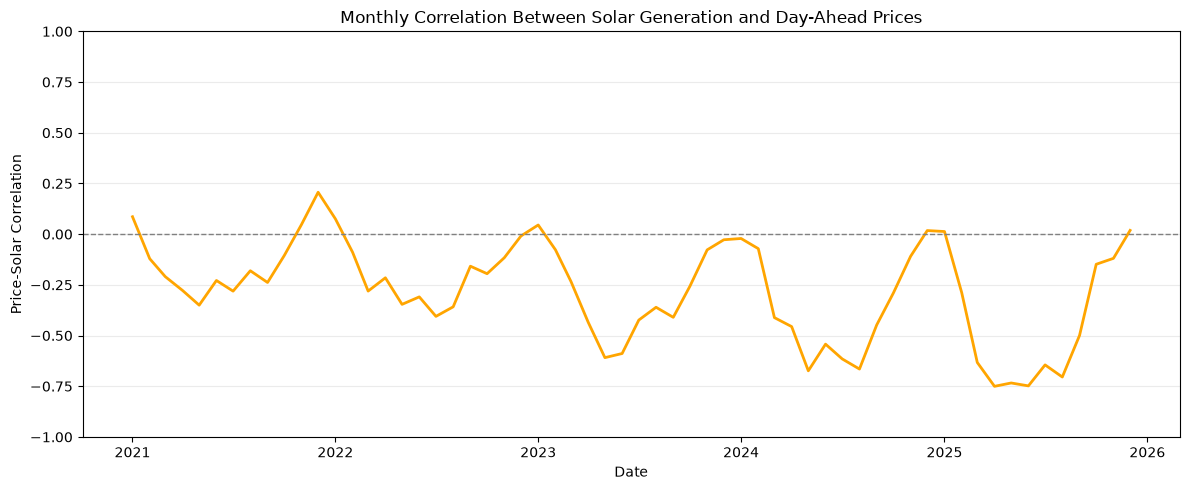

In [223]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_correlation.index,
    monthly_correlation.values,
    color="orange",
    linewidth=2
)

ax.axhline(
    0,
    color="grey",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Monthly Correlation Between Solar Generation and Day-Ahead Prices"
)

ax.set_xlabel("Date")
ax.set_ylabel("Price-Solar Correlation")
ax.set_ylim(-1, 1)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

In [224]:
correlation_df = monthly_correlation.to_frame()

correlation_df["year"] = correlation_df.index.year
correlation_df["month_number"] = correlation_df.index.month

correlation_matrix = correlation_df.pivot(
    index="year",
    columns="month_number",
    values="price_solar_correlation"
)

display(correlation_matrix.round(2))

month_number,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2021,0.09,-0.12,-0.21,-0.28,-0.35,-0.23,-0.28,-0.18,-0.24,-0.11,0.05,0.21
2022,0.08,-0.09,-0.28,-0.22,-0.35,-0.31,-0.41,-0.36,-0.16,-0.20,-0.12,-0.01
2023,0.05,-0.08,-0.23,-0.43,-0.61,-0.59,-0.42,-0.36,-0.41,-0.26,-0.08,-0.03
2024,-0.02,-0.07,-0.41,-0.46,-0.67,-0.54,-0.62,-0.67,-0.45,-0.29,-0.11,0.02
2025,0.01,-0.29,-0.63,-0.75,-0.73,-0.75,-0.64,-0.70,-0.50,-0.15,-0.12,0.02


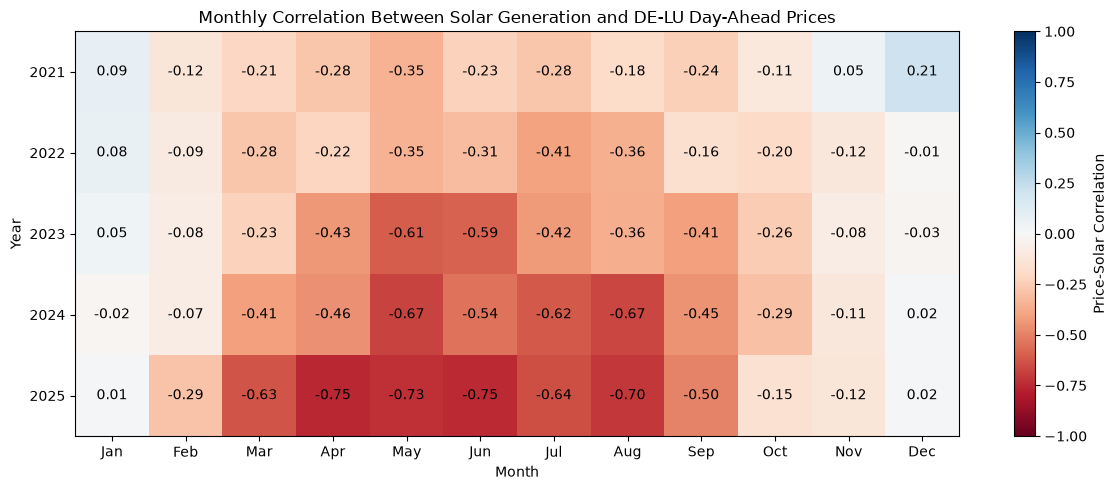

In [225]:
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(12, 5))

heatmap = ax.imshow(
    correlation_matrix.values,
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_yticklabels(correlation_matrix.index)

ax.set_xlabel("Month")
ax.set_ylabel("Year")
ax.set_title(
    "Monthly Correlation Between Solar Generation and DE-LU Day-Ahead Prices"
)

for i in range(correlation_matrix.shape[0]):
    for j in range(correlation_matrix.shape[1]):

        value = correlation_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    heatmap,
    ax=ax,
    label="Price-Solar Correlation"
)

fig.tight_layout()
plt.show()



The monthly analysis shows a clear strengthening of the negative relationship between solar generation and day-ahead electricity prices.

The effect is strongly seasonal. During winter months, hourly solar generation and electricity prices show limited correlation. In contrast, spring and summer increasingly exhibit strong negative correlations.

By 2025, correlations between April and August range from **-0.64 to -0.75**, compared with generally weaker relationships over the same months in 2021.

This suggests that solar generation has become increasingly concentrated in hours associated with lower electricity prices. The effect is consistent with the deterioration observed in solar capture rates and the growing share of photovoltaic generation exposed to negative-price periods.

For a pay-as-produced solar PPA, this represents a material **price-volume correlation risk**: periods of high physical production can coincide with lower market value, meaning that annual baseload prices alone are insufficient to represent the economic value of the generation profile.